# UBI labor-supply simulation: walk-through

How does a **revenue-neutral universal basic income** change hours worked, consumption and welfare when agents differ in wages and non-labor income? This notebook walks through the corrected model in `ubi_sim/`. The README has the summary; here is the working.

Model: each agent maximises $\ln C - \psi\,\frac{e}{1+e}\,m^{1+1/e}$ with $C = y + B + wTm(1-t)$ over the share of time worked $m \in [0,1]$.

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # run from notebooks/ without installing

import numpy as np
from IPython.display import Image, Markdown, display

from ubi_sim import (SENSITIVITY_LEVELS, Params, calibrate_psi, make_population,
                     optimal_hours, run_scenarios, summarize, tax_revenue)
from ubi_sim import plots

FIG = Path.cwd().parent / "figures"
P = Params()
pop = make_population(P)

## 1. The population

1,000 agents with lognormal wages (mean 260, sd 90) and non-labor income (mean 500, sd 300), drawn independently. The seed makes every run reproducible.

wage: mean 261.26  median 247.80  min 82.58  max 898.01


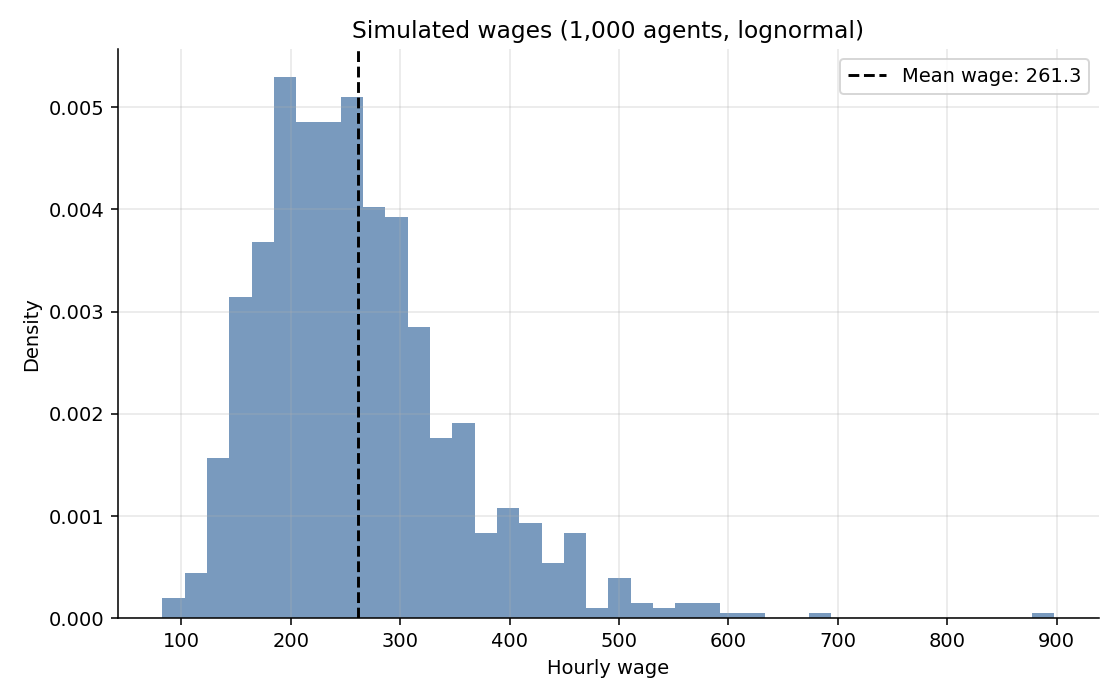

In [2]:
print(f"wage: mean {pop.wages.mean():.2f}  median {np.median(pop.wages):.2f}  min {pop.wages.min():.2f}  max {pop.wages.max():.2f}")
display(Image(plots.wage_distribution(pop, P, FIG)))

## 2. Solving an agent's problem exactly

The first-order condition $\frac{a}{c+am}=\psi m^{1/e}$ has a single root (left side falls, right side rises), so a vectorised bisection solves all agents at once. The residual below confirms the solution.

In [3]:
tax, ubi = 0.30, 5_000.0
m = optimal_hours(pop, tax, ubi, P) / P.T
a = pop.wages * P.T * (1 - tax)
residual = a / (pop.nonlabor + ubi + a * m) - P.psi * m ** (1 / P.frisch)
print(f"max |FOC residual| over {P.n_agents} agents: {np.abs(residual).max():.2e}")
print(f"share of time worked: min {m.min():.4f}, median {np.median(m):.4f}, max {m.max():.4f}")

max |FOC residual| over 1000 agents: 7.77e-16
share of time worked: min 0.9257, median 0.9743, max 0.9919


## 3. Revenue-neutral tax rates

The government must raise baseline revenue **plus** $N \cdot B$. Revenue is a Laffer curve in the tax rate, so the root is bracketed on the rising branch.

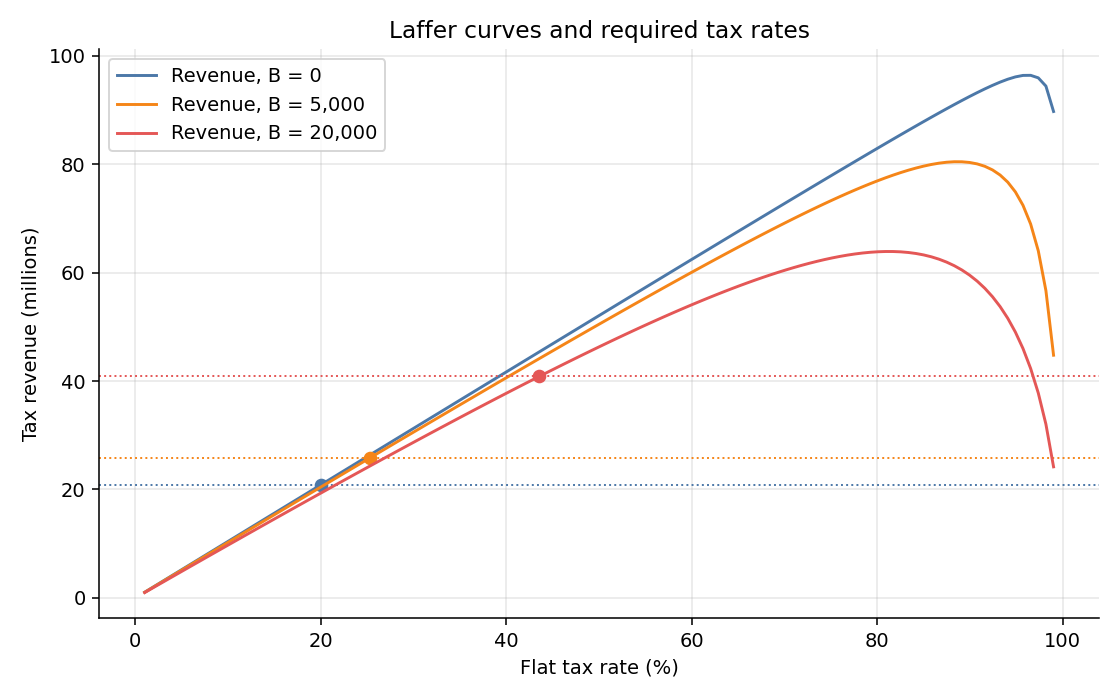

No UBI    B=      0  tax= 20.00%  revenue=  20,858,062  target=  20,858,062
UBI Low   B=  5,000  tax= 25.32%  revenue=  25,858,062  target=  25,858,062
UBI High  B= 20,000  tax= 43.55%  revenue=  40,858,062  target=  40,858,062


In [4]:
scen = run_scenarios(pop, P)
rows = summarize(scen, P)
display(Image(plots.laffer(pop, P, scen, FIG)))
for r in rows:
    s = scen[r["scenario"]]
    print(f"{s.label:9} B={s.ubi:>7,.0f}  tax={100*s.tax:6.2f}%  revenue={s.revenue:>12,.0f}  target={s.target_revenue:>12,.0f}")

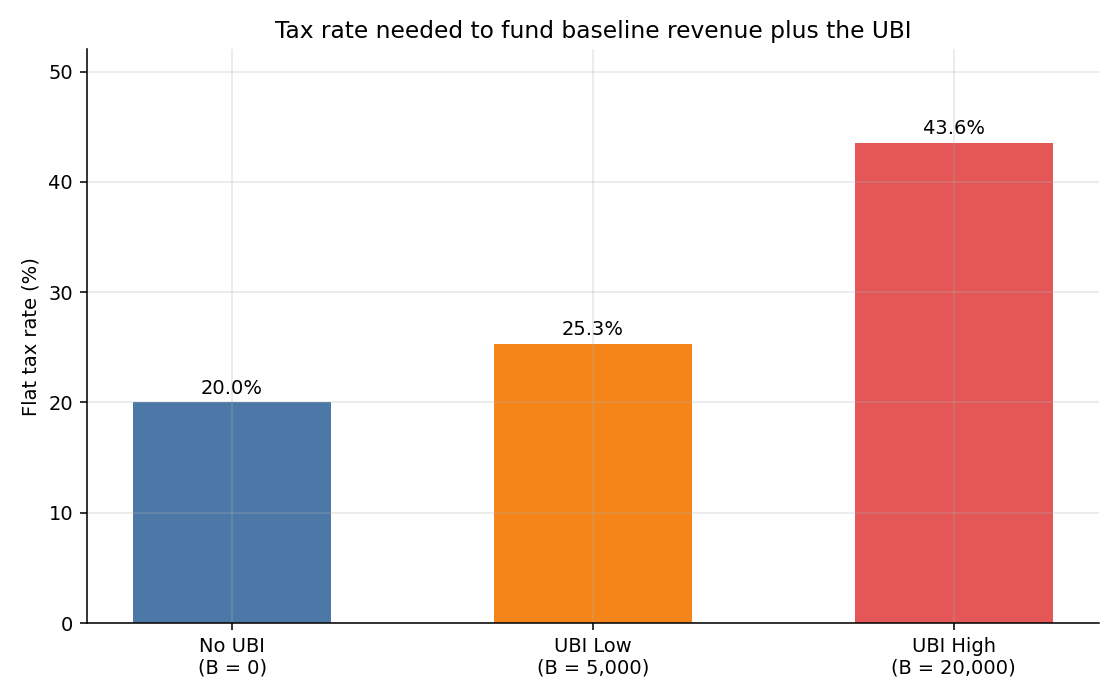

In [5]:
display(Image(plots.tax_rates(scen, FIG)))

## 4. How agents respond

Low-wage agents cut hours the most.

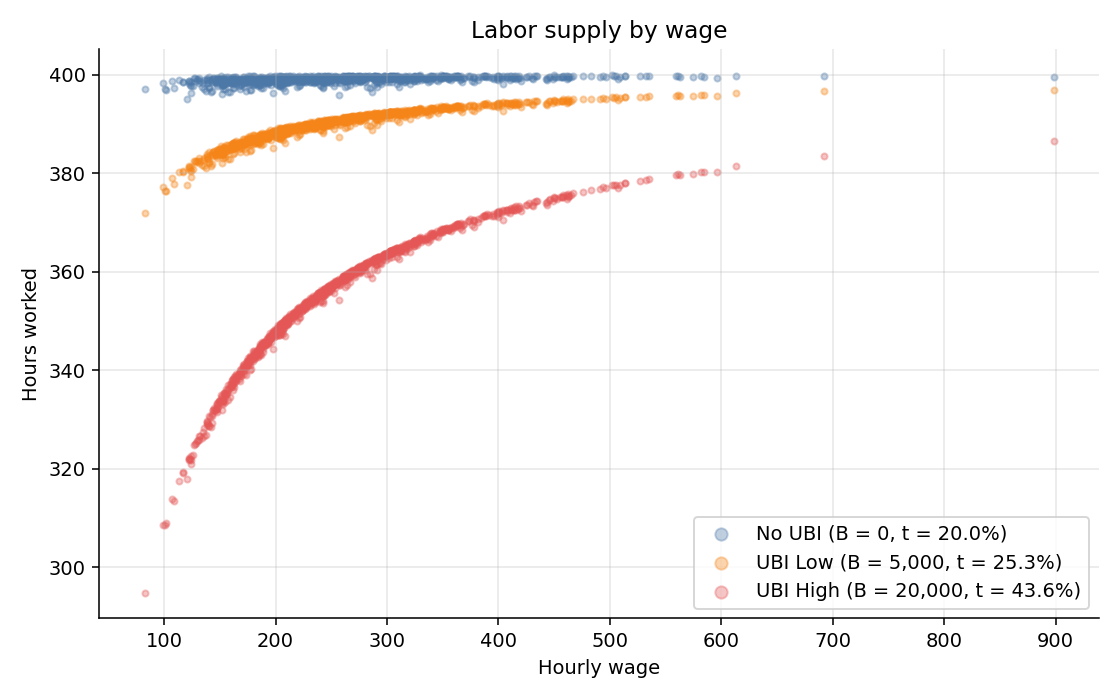

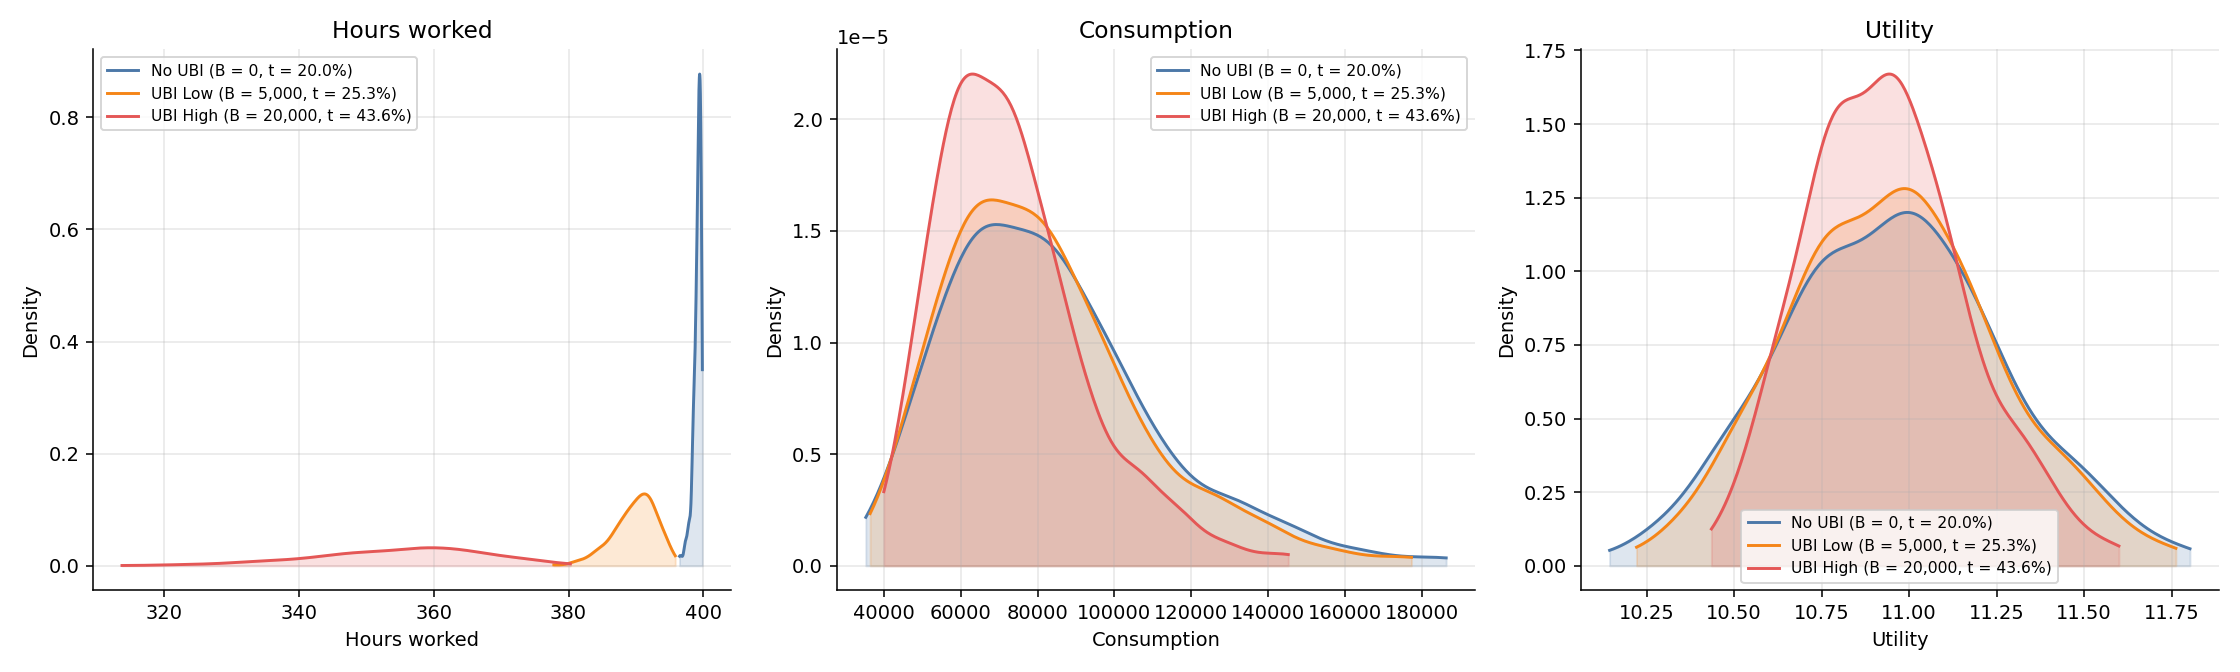

UBI High vs No UBI: lowest-wage decile -17.3% hours, highest-wage decile -6.2%


In [6]:
display(Image(plots.hours_vs_wage(pop, scen, FIG)))
display(Image(plots.distributions(scen, FIG)))
w = pop.wages
lo, hi = w < np.quantile(w, .1), w > np.quantile(w, .9)
b, h = scen["No UBI"].hours, scen["UBI High"].hours
print(f"UBI High vs No UBI: lowest-wage decile {100*(h[lo].mean()/b[lo].mean()-1):.1f}% hours, highest-wage decile {100*(h[hi].mean()/b[hi].mean()-1):.1f}%")

## 5. Welfare

Every scenario uses **its own** hours and **its own** tax rate, so welfare differences reflect the full cost of funding each UBI.

In [7]:
def table(rows):
    cols = [("scenario","Scenario",""),("tax_rate_pct","Tax %",".2f"),("total_hours","Total hours",",.0f"),
            ("gini_consumption","Gini (cons.)",".3f"),("mean_utility","Mean utility",".3f"),
            ("sd_utility","SD utility",".3f"),("bottom_decile_utility","Bottom-decile utility",".3f"),
            ("mean_utility_change_vs_no_ubi","Δ mean utility","+.4f")]
    out = "| " + " | ".join(c[1] for c in cols) + " |\n|" + "---|"*len(cols) + "\n"
    for r in rows:
        out += "| " + " | ".join(r[k] if isinstance(r[k], str) else format(r[k], f) for k,_,f in cols) + " |\n"
    return Markdown(out)
display(table(rows))

| Scenario | Tax % | Total hours | Gini (cons.) | Mean utility | SD utility | Bottom-decile utility | Δ mean utility |
|---|---|---|---|---|---|---|---|
| No UBI | 20.00 | 399,075 | 0.185 | 10.953 | 0.327 | 10.394 | +0.0000 |
| UBI Low | 25.32 | 389,786 | 0.177 | 10.953 | 0.305 | 10.440 | +0.0008 |
| UBI High | 43.55 | 354,956 | 0.147 | 10.937 | 0.233 | 10.568 | -0.0159 |


**Reading it:** inequality falls with UBI (Gini and the spread of utility shrink; the worst-off 10% gain), but *mean* utility is flat at the low level and lower at the high level. The funding tax costs more in lost work and consumption than the transfer adds.

## 6. Sensitivity: a realistic labor-leisure trade-off

With $\psi=1$ the average agent works 99.8% of their time. Calibrating $\psi$ so the average agent works 40% (and adding a middle UBI level):

In [8]:
psi = calibrate_psi(pop, P, 0.40)
P_cal = replace(P, psi=psi)
scen_cal = run_scenarios(pop, P_cal, SENSITIVITY_LEVELS, skip_infeasible=True)
print(f"psi = {psi:.2f}")
display(table(summarize(scen_cal, P_cal)))
missing = [l for l in SENSITIVITY_LEVELS if l not in scen_cal]
from ubi_sim import laffer_peak
for l in missing:
    t_peak, rev_peak = laffer_peak(pop, SENSITIVITY_LEVELS[l], P_cal)
    need = scen_cal["No UBI"].revenue + P.n_agents * SENSITIVITY_LEVELS[l]
    print(f"{l} (B={SENSITIVITY_LEVELS[l]:,.0f}) is INFEASIBLE: max revenue any flat tax can raise = {rev_peak:,.0f} (at {100*t_peak:.0f}%), needed = {need:,.0f}")

psi = 15.36


| Scenario | Tax % | Total hours | Gini (cons.) | Mean utility | SD utility | Bottom-decile utility | Δ mean utility |
|---|---|---|---|---|---|---|---|
| No UBI | 20.00 | 160,000 | 0.184 | 10.052 | 0.324 | 9.500 | +0.0000 |
| UBI Low | 33.88 | 149,963 | 0.163 | 10.049 | 0.268 | 9.611 | -0.0029 |
| UBI Mid | 50.91 | 135,909 | 0.132 | 10.018 | 0.202 | 9.706 | -0.0342 |


UBI High (B=20,000) is INFEASIBLE: max revenue any flat tax can raise = 19,974,393 (at 75%), needed = 28,365,643


## 7. Robustness across random populations

100 independent populations per calibration (run with `python -m ubi_sim.run`; this takes ~30 s).

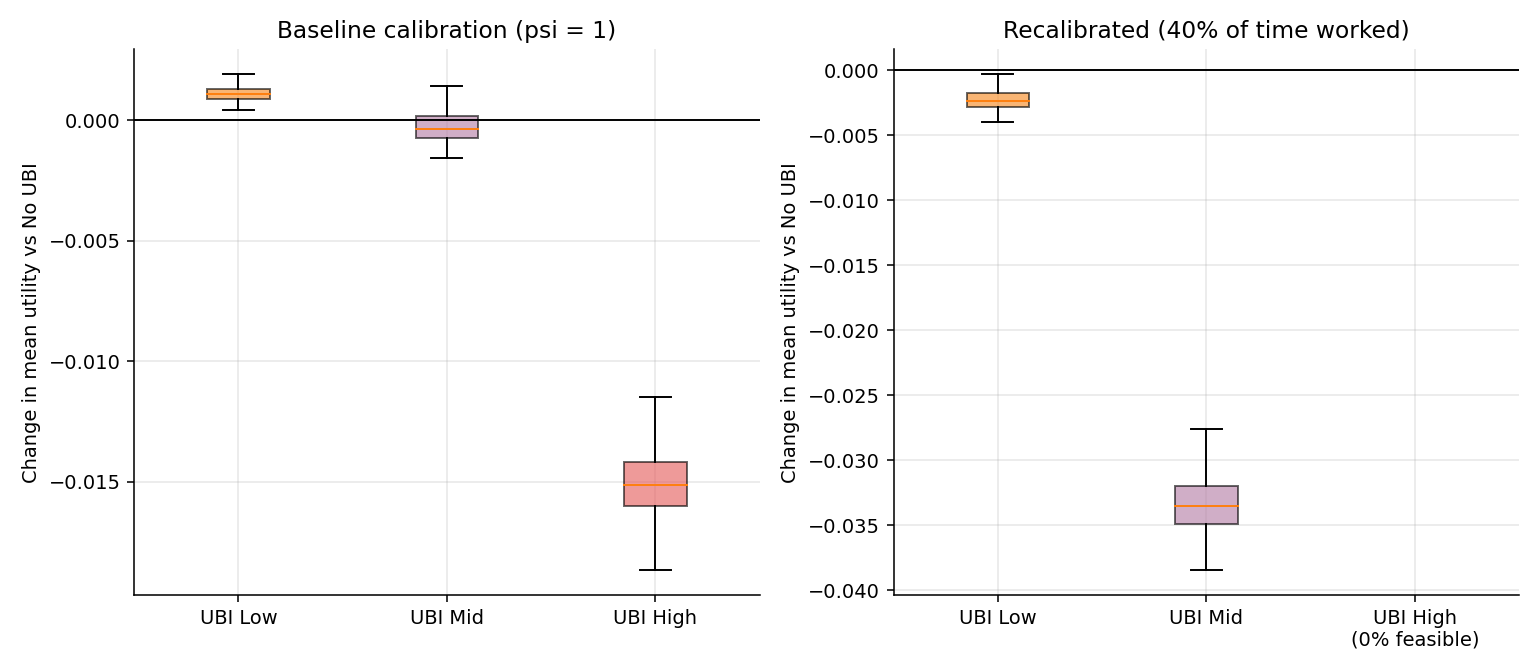

## Robustness over 100 random populations

| Calibration | Scenario | Share of seeds feasible | Mean Δ utility vs No UBI | SD across seeds | Share of seeds with Δ > 0 |
|---|---|---|---|---|---|
| Baseline calibration (psi = 1) | UBI Low | 100% | +0.0011 | 0.0003 | 100% |
| Baseline calibration (psi = 1) | UBI Mid | 100% | -0.0003 | 0.0007 | 30% |
| Baseline calibration (psi = 1) | UBI High | 100% | -0.0151 | 0.0016 | 0% |
| Recalibrated (40% of time worked) | UBI Low | 100% | -0.0023 | 0.0009 | 0% |
| Recalibrated (40% of time worked) | UBI Mid | 100% | -0.0334 | 0.0024 | 0% |
| Recalibrated (40% of time worked) | UBI High | 0% | n/a | n/a | n/a |


In [9]:
display(Image(FIG / "seed_robustness.png"))
display(Markdown((Path.cwd().parent / "results" / "RESULTS.md").read_text().split("## Robustness")[1].join(["## Robustness", ""])))

## Limitations

Partial equilibrium (wages fixed), static one-period model, flat labor tax, no participation margin, illustrative calibration, utilitarian welfare over ordinal utilities. See the README.